# Python DA Assignment 2 - Data Visualization

**1) Loading the Taxis Dataset**

import seaborn as sns

Load the 'taxis' dataset

df = sns.load_dataset("taxis")

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=sns.load_dataset("taxis")
df.head()


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


**imported the libraries. Then loaded the "taxis" dataset using Seaborn and displayed the first five rows**

**2) Handling Missing Values**

➢ Check for missing values in the dataset and identify columns with missing data.

➢ Impute missing values using appropriate strategies based on the column type (e.g., using mean, median, or mode for numerical columns, and mode for categorical columns).

➢ For columns that are critical and cannot be reasonably imputed, remove rows with missing values to maintain data integrity.

In [3]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


isnull().sum() is used to check how many missing values are present in each column.

In [4]:
df["payment"]=df["payment"].fillna(df["payment"].mode()[0])
df["pickup_zone"]=df["pickup_zone"].fillna(df["pickup_zone"].mode()[0])
df["dropoff_zone"]=df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0])
df["pickup_borough"]=df["pickup_borough"].fillna(df["pickup_borough"].mode()[0])
df["dropoff_borough"]=df["dropoff_borough"].fillna(df["dropoff_borough"].mode()[0])

In [5]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


**I found missing values in the categorical columns like payment,pickup_zone,dropoff_zone,pickup_borough and dropoff_borough.I filled these missing values using fillna() and mode().I used mode because it gives the most repeated value in each column.**

In [6]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


**checked the dataset for missing values.Since there were no missing values in the critical columns,I did not remove any rows.**

# 3) Visualizations using Matplotlib/Pandas Plot:

**Line Chart**

Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime format before plotting.

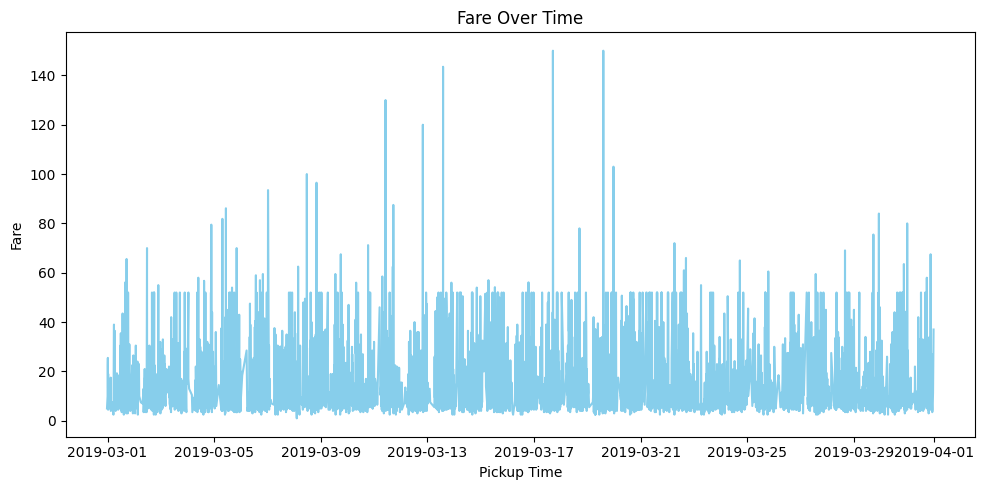

In [12]:
df["pickup"]=pd.to_datetime(df["pickup"])
data=df.sort_values("pickup")
plt.figure(figsize=(10,5))
plt.plot(data["pickup"], data["fare"],color="skyblue")
plt.title("Fare Over Time")
plt.xlabel("Pickup Time")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

**Here i converted the pickup column into datetime format and sorted the data by pickup time.Then created a line chart to show how taxi fares change over time.I used pickup time on the X-axis and fare on the Y-axis.Then changed the line colour to skyblue and added a title and labels to make the chart easy to understand.**

**Bar Chart**

Create a bar chart to show the total fare for each pickup_borough. Group the data by pickup_borough and sum the fare for each group.

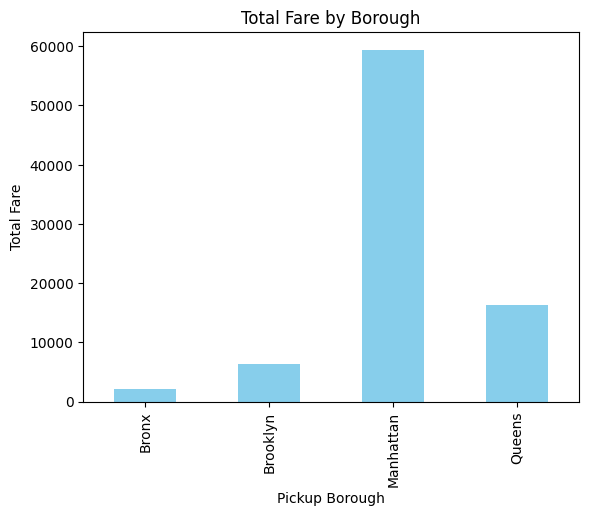

In [8]:
fare=df.groupby("pickup_borough")["fare"].sum()
fare.plot(kind="bar", color="skyblue")
plt.title("Total Fare by Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.show()

**grouped the data by pickup borough and calculated the total fare for each borough.Then displayed the result using a bar chart.**

**Pie Chart**

Plot a pie chart showing the distribution of trips based on the payment method (credit
card, cash, etc.). Each slice should represent the count of trips for a specific payment
method.

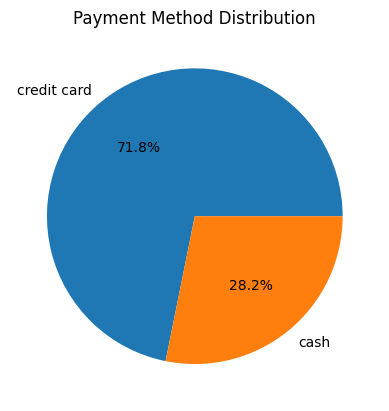

In [9]:
payment=df["payment"].value_counts()
plt.pie(payment,labels=payment.index, autopct="%1.1f%%")
plt.title("Payment Method Distribution")
plt.show()

**counted the number of trips for each payment method and created a pie chart to show their percentages.**

**Histogram**

Create a histogram to visualize the distribution of distance. Customize the number of
bins for better granularity and ensure the plot is easy to interpret.

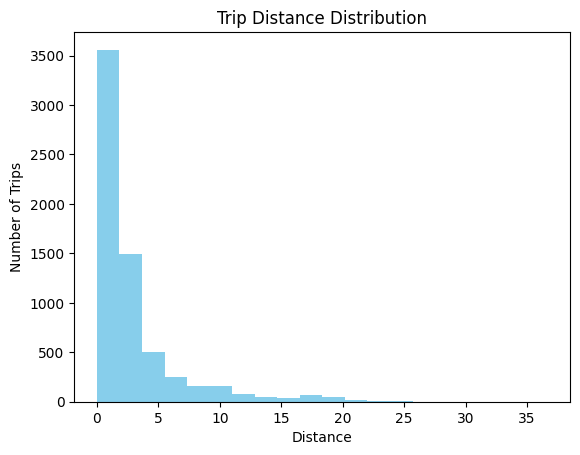

In [17]:
plt.hist(df["distance"],bins=20,color="skyblue")
plt.title("Trip Distance Distribution")
plt.xlabel("Distance")
plt.ylabel("Number of Trips")
plt.show()

**created a histogram to understand the distribution of trip distances,used 20 bins to divide the distances into groups.**

**Box Plot**

Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
Use pickup_borough as the categorical axis and tip as the numeric axis.

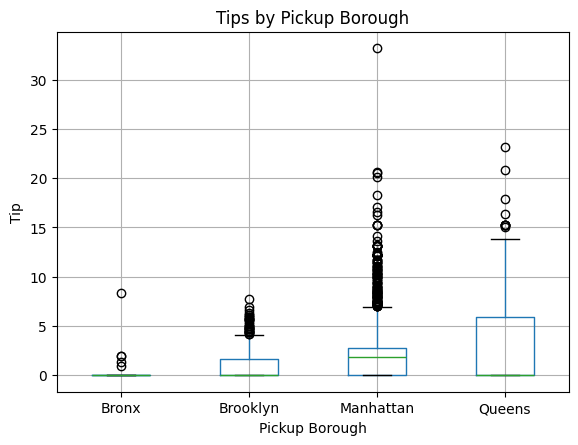

In [18]:
df.boxplot(column="tip",by="pickup_borough")
plt.title("Tips by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip")
plt.show()

**This code creates a box plot to compare tip amounts in different pickup boroughs.It helps us see the variation and unusual tip amounts.**

# Visualizations using Seaborn:

**Count Plot**

Create a count plot to visualize the number of trips in each pickup_borough. The
x-axis should represent the boroughs, and the y-axis should show the count of trips.

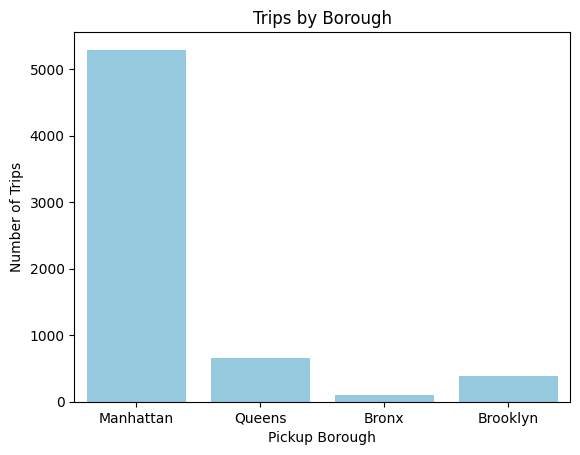

In [21]:
sns.countplot(data=df,x="pickup_borough",color="skyblue")
plt.title("Trips by Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.show()

**created a count plot using Seaborn to find the number of taxi trips from each pickup borough,we can use pickup_borough on the X-axis and the number of trips on the Y-axis.Each bar represents a borough,and the height of the bar shows how many trips started there.**

**Scatter Plot**

Plot a scatter plot to show the relationship between distance and fare. Use
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
points based on the pickup_borough to differentiate the trips by their respective
boroughs.

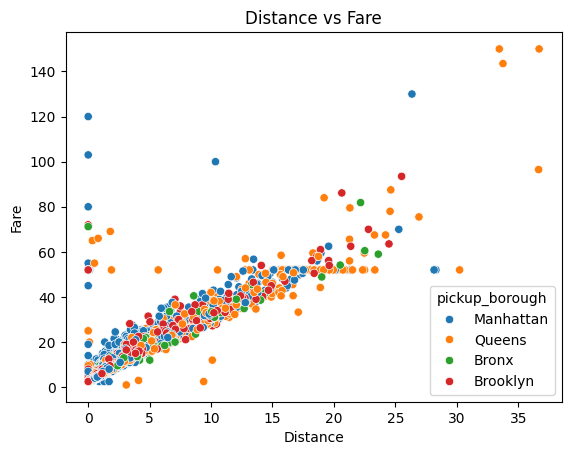

In [22]:
sns.scatterplot(data=df,x="distance",y="fare",hue="pickup_borough")
plt.title("Distance vs Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.show()

**created a scatter plot using Seaborn to understand the relationship between trip distance and fare. I placed distance on the X-axis and fare on the Y-axis. Each dot represents one taxi trip. I used hue="pickup_borough" to show trips from different boroughs in different colors.**

**Heatmap**

Plot a heatmap to visualize the correlation between numerical variables such as
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
relationships.

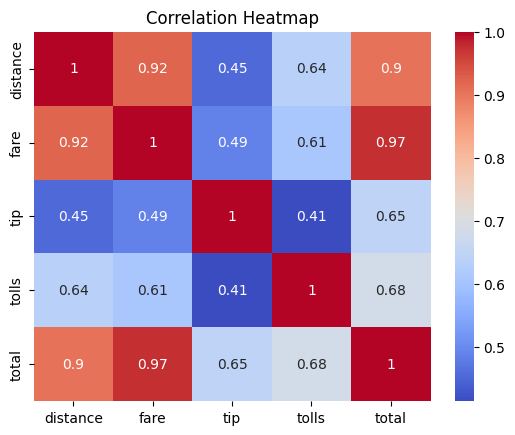

In [23]:
data=df[["distance","fare","tip","tolls","total"]]
sns.heatmap(data.corr(),annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

**Created a heatmap using Seaborn to check the relationship between distance, fare,tip,tolls and total.Here i used corr() to calculate the correlation, annot=True to display the values and cmap="coolwarm" for colors.This chart helps to identify strong and weak relationships between numerical columns.**

**Pair Plot**

Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
and total. Color the data points according to the pickup_zone method to compare
how different zones affect these variables.

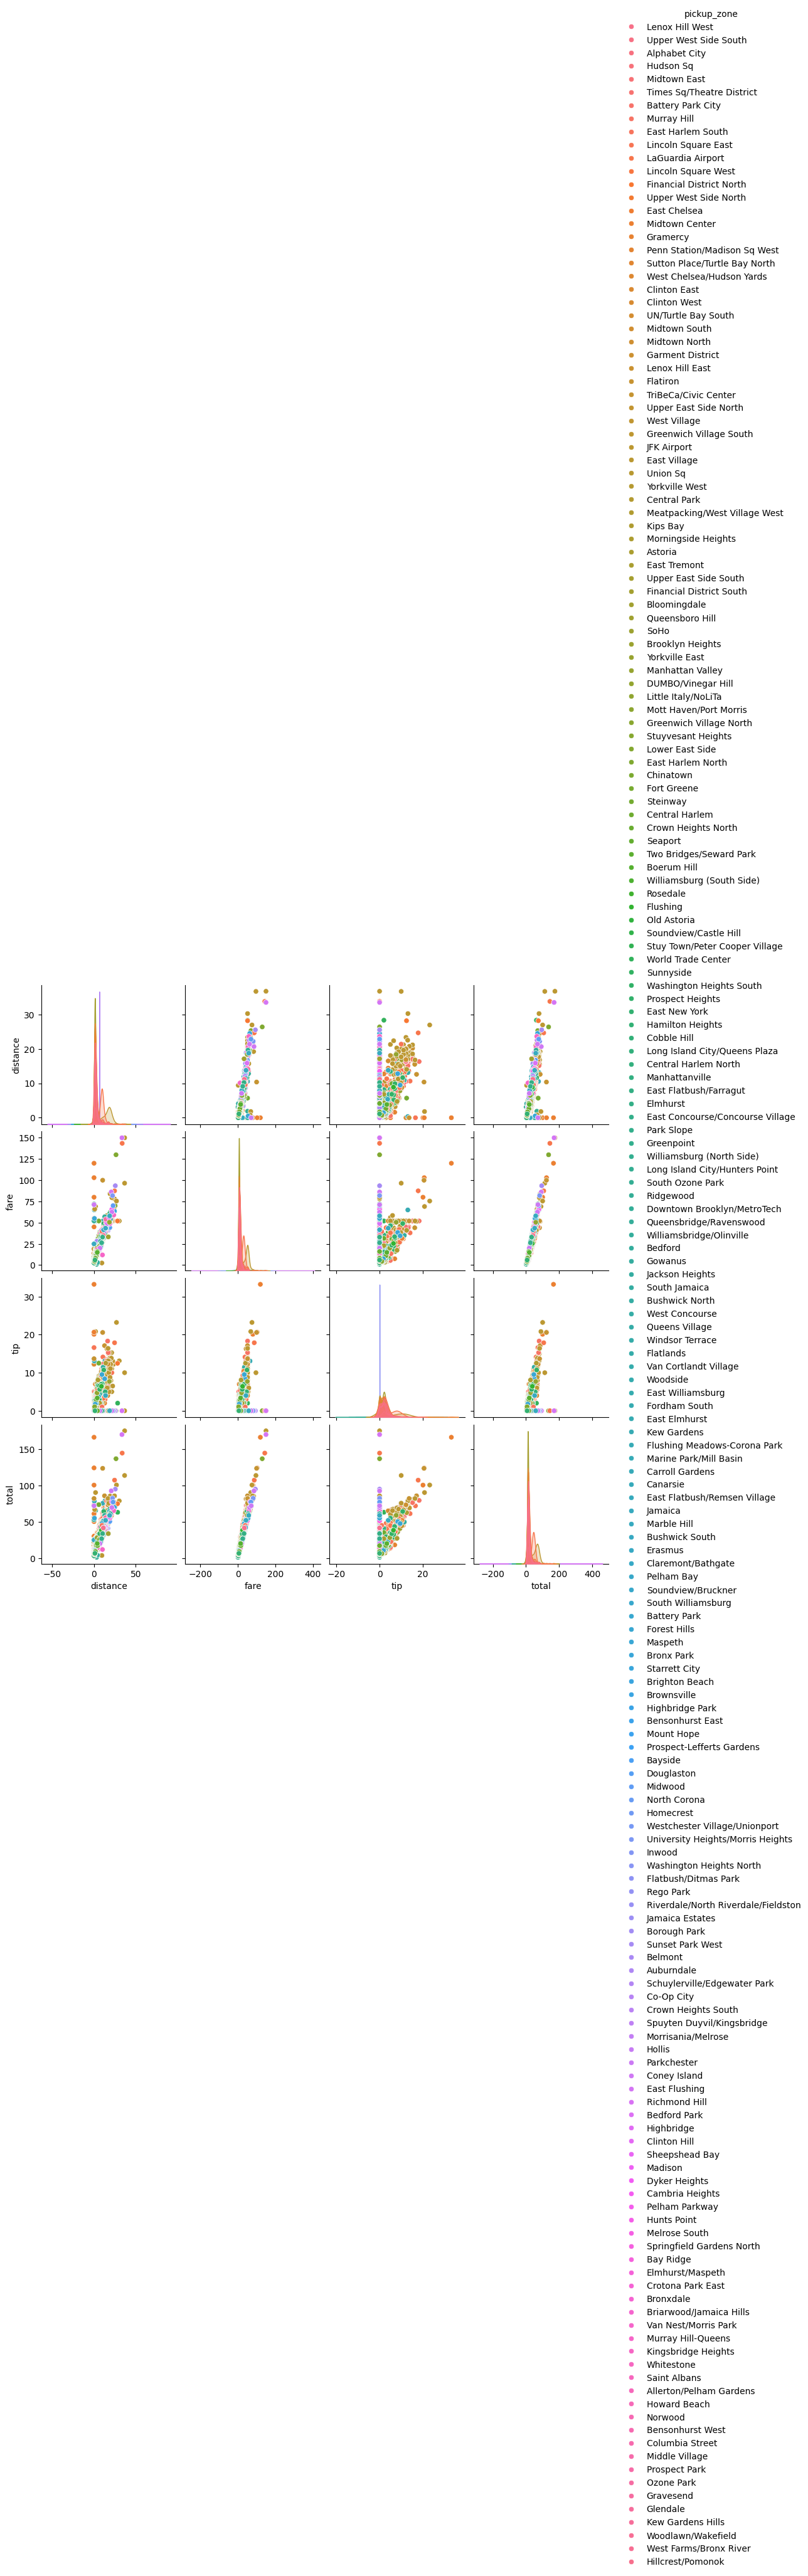

In [25]:
sns.pairplot(df,vars=["distance","fare","tip","total"],hue="pickup_zone")
plt.show()

**Created a pair plot to compare distance, fare, tip, and total. I used hue="pickup_zone" to show different pickup zones in different colors.**

**Violin Plot**

Plot a violin plot to show the distribution of fare for each payment method. Use the
payment method as the categorical axis and fare as the numeric axis to visualize its
distribution.

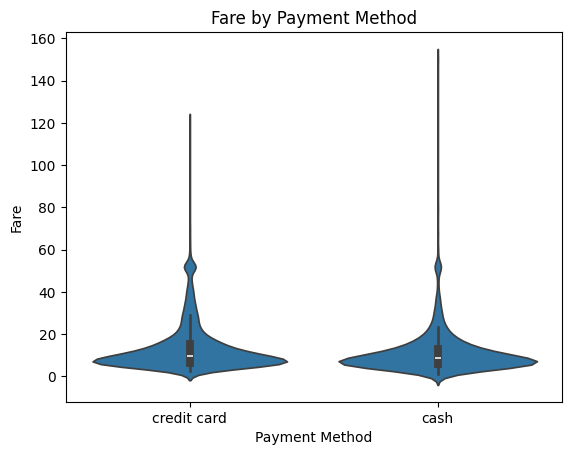

In [26]:
sns.violinplot(data=df,x="payment",y="fare")
plt.title("Fare by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.show()

**Created a violin plot to compare the fare distribution for different payment methods.It shows where fare values are more concentrated.**